# Data augmentation MCMC: when infection times are missing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gem-epidemics/colab/blob/master/eitv/data_augmentation_workshop.ipynb)

This 90-minute workshop follows on from *A network model for the 1861 Hagelloch measles epidemic*.  There, we estimated the parameters of a network SIR model assuming that we knew when every child was infected.  In real outbreaks, we almost never know this: we observe symptoms, test results or recoveries, but not the moment of infection.

**Data augmentation** gets around this by treating the missing infection times as extra unknowns, and sampling them with MCMC alongside the parameters.  We'll see the idea, explore how its central step works on a small example, and then use `gemlib` to apply it to the Hagelloch epidemic.

| Part | Topic | Time |
|---|---|---|
| 1 | Missing data in epidemics | ~10 min |
| 2 | The idea of data augmentation | ~15 min |
| 3 | Moving infection times | ~25 min |
| 4 | Data augmentation for Hagelloch in `gemlib` | ~35 min |
| | Wrap-up | ~5 min |

## LEARNING OUTCOMES
- Explain why missing event times make the likelihood of an epidemic model intractable
- Describe how data augmentation MCMC samples the joint posterior of parameters and missing event times
- Explain how the "move events" sampler proposes new infection times, and how its settings affect mixing
- Recognise the boundary cases (left and right censoring, unobserved infections) that other samplers handle
- Build a data augmentation MCMC sampler in `gemlib`, and compare its posterior predictive distribution with one that assumes infection times are known

Run the cells from top to bottom. Exercises have hidden solutions below them; try the
exercise first, then expand the solution if you get stuck.

```{tip}
The MCMC runs in Part 4 take about 10 minutes in total.  Your instructor may ask you to run the two setup cells and then the cells under **Running the samplers** in Part 4 straight away, and to work through Parts 1 to 3 while they run.
```

## References
- Neal, P. J. and Roberts, G. O. (2004). Statistical inference and model selection for the 1861 Hagelloch measles epidemic. _Biostatistics_ __5__(2): 249–261. [doi:10.1093/biostatistics/5.2.249](https://doi.org/10.1093/biostatistics/5.2.249)
- Jewell, C. P., Kypraios, T., Neal, P. and Roberts, G. O. (2009). Bayesian analysis for emerging infectious diseases. _Bayesian Analysis_ __4__(3): 465–496. [doi:10.1214/09-BA417](https://projecteuclid.org/journals/bayesian-analysis/volume-4/issue-3/Bayesian-analysis-for-emerging-infectious-diseases/10.1214/09-BA417.full)

## Setup

If you are using Google Colab, uncomment and run the `pip install` line first.  These notebooks need `gemlib` version 0.16.3 or later.

The second cell repeats everything we built in the previous workshop: it loads the Hagelloch data, builds the event array `events` and `initial_conditions`, defines the model `hagelloch_sir(...)`, the Bayesian model `joint_model`, and the parameter sampler `param_kernel`.  It also defines some plotting helpers.  **Just run it**; you can expand it if you'd like a reminder of the details.

In [1]:
# !pip install "gemlib>=0.16.3"

import urllib.request

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
import xarray as xr

import gemlib

jax.config.update("jax_enable_x64", True)   # use double precision: the Hagelloch data need it

gld = gemlib.distributions
mcmc = gemlib.mcmc
tfd = tfp.distributions
tfb = tfp.bijectors

In [2]:
# ---------------------------------------------------------------------------
# Recap of the previous workshop, plus plotting helpers.  Just run this cell!
# ---------------------------------------------------------------------------

# --- The Hagelloch data, as an event array [T, N, 2] and initial conditions [N, 3]

url = "https://gem-epidemics.gitlab.io/practical-epidemics/_static/iddinf/hagelloch.nc"
urllib.request.urlretrieve(url, "hagelloch.nc")   # download the file to the current folder
hagelloch = xr.load_dataset("hagelloch.nc")

num_individuals = hagelloch["si_time"].shape[0]
max_time = int(hagelloch["ir_time"].max())
everyone = np.arange(num_individuals)      # 0, 1, ..., 186

# An empty [time, individual, transition] array
events = np.zeros((max_time + 1, num_individuals, 2))

# Put a 1 at [infection time, individual, 0] and [removal time, individual, 1]
events[hagelloch["si_time"], everyone, 0] = 1.0   # S->I events
events[hagelloch["ir_time"], everyone, 1] = 1.0   # I->R events

# Drop day 0: we condition on the first infection, which starts the epidemic
events = events[1:]
num_steps = events.shape[0]

# The state of each individual just before day 1: one row per child, columns S, I, R
initial_conditions = np.zeros((num_individuals, 3))
initial_conditions[:, 0] = 1.0                                # everyone susceptible...
index_case = np.where(hagelloch["si_time"] == 0)[0]
initial_conditions[index_case, :] = [0.0, 1.0, 0.0]           # ...except the index case

# --- The network SIR model

# Connectivity matrices from the dataset
M_household = hagelloch["household_mat"].values
M_class1 = hagelloch["class1_mat"].values
M_class2 = hagelloch["class2_mat"].values
M_distance = hagelloch["distance_mat"].values
kappa = 30.0   # centring constant for distance

sir_incidence_matrix = np.array([
    # SI  IR
    [-1,  0],   # S
    [ 1, -1],   # I
    [ 0,  1],   # R
])


def hagelloch_sir(household, class1, class2, distance, spatial_decay, removal_rate,
                  initial_conditions, name="sir"):
    "Build the Hagelloch network SIR model for given parameter values."

    def si_rate(t, state):
        contact = (
            household * M_household
            + class1 * M_class1
            + class2 * M_class2
            + distance * jnp.exp(-spatial_decay * (M_distance - kappa))
        )
        return contact @ state[:, 1]   # weighted number of infectious contacts of each child

    def ir_rate(t, state):
        return removal_rate

    return gld.DiscreteTimeStateTransitionModel(
        transition_rate_fn=[si_rate, ir_rate],
        incidence_matrix=sir_incidence_matrix,
        initial_state=initial_conditions,
        num_steps=num_steps,
        name=name,
    )

# --- The Bayesian model

@tfd.JointDistributionCoroutineAutoBatched
def joint_model():
    household = yield tfd.Exponential(np.float64(10.0), name="household")
    class1 = yield tfd.Exponential(np.float64(10.0), name="class1")
    class2 = yield tfd.Exponential(np.float64(10.0), name="class2")
    distance = yield tfd.Exponential(np.float64(10.0), name="distance")
    spatial_decay = yield tfd.Exponential(np.float64(20.0), name="spatial_decay")
    removal_rate = yield tfd.Exponential(np.float64(10.0), name="removal_rate")

    # Each child independently starts S (prob 0.99) or I (prob 0.01)
    initial_conditions = yield tfd.Sample(
        tfd.Multinomial(1, probs=np.array([0.99, 0.01, 0.0])),
        sample_shape=num_individuals,
        name="initial_conditions",
    )

    yield hagelloch_sir(household, class1, class2, distance, spatial_decay, removal_rate,
                        initial_conditions, name="sir")

# --- Metropolis-within-Gibbs steps for the six parameters

def log_rwmh(param_name, scale):
    "A random walk Metropolis-Hastings step for one parameter, on the log scale."
    return mcmc.MwgStep(
        mcmc.transform_sampling_algorithm(
            bijectors=tfb.Exp(),
            sampling_algorithm=mcmc.rwmh(scale=scale),
        ),
        target_names=param_name,
    )


param_kernel = (
    log_rwmh("household", 0.5)
    >> log_rwmh("class1", 0.5)
    >> log_rwmh("class2", 0.5)
    >> log_rwmh("distance", 0.4)
    >> log_rwmh("spatial_decay", 1.2)
    >> log_rwmh("removal_rate", 0.25)
)

# --- Plotting and summary helpers

PARAM_NAMES = ["household", "class1", "class2", "distance", "spatial_decay", "removal_rate"]


def plot_incidence(events, simulations=None, title=None):
    """Daily S->I and I->R events (shape [T, N, 2]), optionally over simulations of shape [B, T, N, 2]."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for r, (ax, label) in enumerate(zip(axes, ["S->I (infections)", "I->R (removals)"])):
        days = np.arange(1, events.shape[0] + 1)
        if simulations is not None:
            sims = np.asarray(simulations)[..., r].sum(axis=-1)
            ax.plot(days, sims.T, color=f"C{r}", alpha=0.08)
            ax.plot([], [], color=f"C{r}", alpha=0.5, label="Simulated")
        ax.plot(days, np.asarray(events)[..., r].sum(axis=-1), color="black", lw=2, label="Observed")
        ax.set_title(label)
        ax.set_xlabel("Day")
        ax.legend()
    axes[0].set_ylabel("Events per day")
    if title is not None:
        fig.suptitle(title)
    plt.show()


def plot_states(states, labels=("S", "I", "R"), alpha=1.0):
    """Number of individuals in each state over time; states has shape [..., T, N, 3]."""
    totals = np.asarray(states).sum(axis=-2)          # add up over individuals
    totals = totals.reshape(-1, *totals.shape[-2:])   # [simulations, T, 3]
    fig, ax = plt.subplots(figsize=(8, 4))
    for k, label in enumerate(labels):
        ax.plot(totals[..., k].T, color=f"C{k}", alpha=alpha)
        ax.plot([], [], color=f"C{k}", label=label)
    ax.set_xlabel("Day")
    ax.set_ylabel("Individuals")
    ax.legend()
    plt.show()


def autocorrelation(x, max_lag=100):
    x = np.asarray(x) - np.mean(x)
    return np.array([1.0] + [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, max_lag + 1)])


def trace_plots(samples, burn_in=1000, names=PARAM_NAMES):
    """Trace plot, histogram and autocorrelation for each parameter, after burn-in."""
    fig, axes = plt.subplots(len(names), 3, figsize=(15, 2.5 * len(names)))
    for row, name in zip(axes, names):
        draws = np.asarray(getattr(samples, name))[burn_in:]
        row[0].plot(draws, lw=0.5)
        row[0].set_ylabel(name)
        row[1].hist(draws, bins=40, density=True, alpha=0.7)
        row[2].bar(np.arange(101), autocorrelation(draws), width=1.0)
    axes[0, 0].set_title("Trace")
    axes[0, 1].set_title("Posterior density")
    axes[0, 2].set_title("Autocorrelation")
    axes[-1, 0].set_xlabel("Iteration (after burn-in)")
    axes[-1, 2].set_xlabel("Lag")
    fig.tight_layout()
    plt.show()


def summarise(samples, burn_in=1000, names=PARAM_NAMES):
    """Posterior mean, 95% credible interval and effective sample size for each parameter."""
    print(f"{'parameter':<15}{'mean':>10}{'2.5%':>10}{'97.5%':>10}{'ESS':>8}")
    for name in names:
        draws = np.asarray(getattr(samples, name))[burn_in:]
        lo, hi = np.quantile(draws, [0.025, 0.975])
        ess = float(tfp.mcmc.effective_sample_size(draws))
        print(f"{name:<15}{draws.mean():>10.4f}{lo:>10.4f}{hi:>10.4f}{ess:>8.0f}")


def infection_days(events):
    """Day of each individual's infection, from events of shape [..., T, N, 2]."""
    return np.argmax(np.asarray(events)[..., 0], axis=-2)


def plot_infection_time_posteriors(trace, true_times, people):
    """Trace and posterior histogram of the infection time of selected individuals."""
    fig, axes = plt.subplots(2, len(people), figsize=(4 * len(people), 6))
    for k, person in enumerate(people):
        axes[0, k].plot(trace[:, person], lw=0.5)
        axes[0, k].set_title(f"Individual {person}")
        axes[0, k].set_xlabel("Iteration")
        axes[1, k].hist(trace[:, person], bins=np.arange(trace[:, person].min() - 0.5, trace[:, person].max() + 1.5),
                        density=True, alpha=0.7)
        axes[1, k].axvline(true_times[person], color="red", ls="--", label="True time")
        axes[1, k].set_xlabel("Infection day")
    axes[0, 0].set_ylabel("Infection day")
    axes[1, 0].set_ylabel("Posterior probability")
    axes[1, 0].legend()
    fig.tight_layout()
    plt.show()


def compare_posteriors(samples_a, samples_b, labels, burn_in=1000, names=PARAM_NAMES):
    """Overlaid posterior histograms of each parameter from two MCMC runs."""
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, name in zip(axes.flatten(), names):
        for s, label in zip([samples_a, samples_b], labels):
            ax.hist(np.asarray(getattr(s, name))[burn_in:], bins=40, density=True, alpha=0.5, label=label)
        ax.set_title(name)
    axes[0, 0].legend()
    fig.tight_layout()
    plt.show()

## Part 1: Missing data in epidemics

Here are the first few rows of the Hagelloch data as a **line list**, one row per child:

In [3]:
line_list = pd.DataFrame({
    "infection day": hagelloch["si_time"].values,
    "removal day": hagelloch["ir_time"].values,
})
line_list.head(8)

,infection day,removal day
0,22,30
1,24,32
2,29,37
3,28,33
4,23,32
5,27,34
6,25,33
7,22,31


For measles, infection happens around 10 days before the first symptoms.  Nobody in 1861 saw these children being infected: what was actually recorded were the dates when symptoms appeared.  Honestly, then, our data look more like this:

In [4]:
censored_line_list = line_list.copy()
censored_line_list["infection day"] = np.nan   # NaN plays the role of NA in R
censored_line_list.head(8)

,infection day,removal day
0,NaN,30
1,NaN,32
2,NaN,37
3,NaN,33
4,NaN,32
5,NaN,34
6,NaN,33
7,NaN,31


In the previous workshop we filled in the `NaN`s with infection times worked back from symptom dates, and then treated them as if they were observed.  That ignores our uncertainty about them, and if they're wrong, it can bias our estimates.

### Why can't we just use the likelihood?

Recall from the likelihood workshop how we wrote down the likelihood of an epidemic: as a product over days and transitions of Binomial probabilities,

$$
L(\theta) = \prod_{t}\prod_{(q,r)} \Pr\left(y^{qr}_t \mid x_t, \theta\right),
$$

where each term needs the **state** $x_t$ of the population on day $t$: who is susceptible, who is infectious.  If we don't know the infection times, we don't know $x_t$, and we can't evaluate any of the terms.

In principle, the likelihood of what we _did_ observe (the removal times $y$) is a sum over every possible set of infection times $X$ that is consistent with them:

$$
L(\theta; y) = \sum_{X} \Pr(y, X \mid \theta).
$$

But this sum is enormous.  If each of the 186 infected children could plausibly have been infected on any of, say, 10 different days, there are $10^{186}$ possible sets of infection times, far more than there are atoms in the universe (about $10^{80}$).  We can't compute this sum, so we can't compute the likelihood.


----

## Part 2: The idea of data augmentation

The trick is to stop trying to sum over the missing infection times, and instead treat them as **extra unknowns**, just like the parameters.  We then sample the **joint** posterior of the parameters $\theta$ and the complete epidemic $X$ (all the infection and removal times), given the observed data $y$:

$$
\pi(\theta, X \mid y) \propto \underbrace{\Pr(y \mid X)}_{\text{observation}}\; \underbrace{\Pr(X \mid \theta)}_{\text{epidemic model}}\; \underbrace{\pi(\theta)}_{\text{prior}}.
$$

Every term is easy to compute:

- $\Pr(X \mid \theta)$ is the likelihood of a _complete_ epidemic, which is exactly what `gemlib`'s `log_prob` gives us;
- $\Pr(y \mid X)$ is 1 if the complete epidemic $X$ agrees with what we observed (here, if it has the right removal times) and 0 otherwise;
- $\pi(\theta)$ is the prior, as before.

```{mermaid}
:name: da-dag
:alt: Data augmentation DAG
:caption: The parameters generate a complete epidemic, of which we only observe part.

---
config:
  look: handDrawn
  theme: neutral
---

flowchart TD
  T((θ)) --> X((Complete<br>epidemic X))
  X --> Y((Observed<br>data y))
```

### Metropolis-within-Gibbs, again

We sample this joint posterior by alternating between two kinds of step, exactly like the Metropolis-within-Gibbs sampler from the previous workshop, where we updated one parameter at a time:

1. **Update the parameters** given the current infection times: draw $\theta$ from $\pi(\theta \mid X, y)$.  With $X$ fixed, this is _exactly_ the problem we solved in the previous workshop, so we can reuse `param_kernel`.
2. **Update the infection times** given the current parameters: draw $X$ from $\pi(X \mid \theta, y)$.  There's no simple formula for this, so we use Metropolis-Hastings steps that propose changes to the infection times and accept or reject them.

Repeat many times.

The payoff is that if we simply ignore the $X$ part of each sample, the $\theta$ samples are draws from $\pi(\theta \mid y)$: the posterior given only what we _actually_ observed.  The MCMC has done the impossible sum over infection times for us, by Monte Carlo.  As a bonus, the $X$ samples tell us what the infection times probably were.


----

## Part 3: Moving infection times

Step 2 of the sampler needs a way to propose new infection times.  The simplest is to pick one infection and move it a few days earlier or later.  This is called the **move events** algorithm:

```{prf:algorithm} The move events algorithm for an individual-level model
:label: alg-move-events

1. Choose an infection to move, at random from all the infections.
2. Choose a new day for it: up to $\delta_{max}$ days earlier or later than its current day, with every possibility equally likely.  If the new day falls outside the observation window, reject the proposal.
3. Accept the moved infection with probability
   $$\alpha = \min\left(1, \frac{\pi(\text{epidemic with the infection moved} \mid \theta, y)}{\pi(\text{current epidemic} \mid \theta, y)}\right),$$
   otherwise keep the current epidemic.
```

Step 3 is exactly the Metropolis-Hastings accept/reject step from the Bayes and MCMC workshop: a move to a more probable epidemic is always accepted, and a move to a less probable one only sometimes.  The size of the move, $\delta_{max}$, plays the same role as the proposal `scale` of the random walk sampler.

We never need to check whether a proposed move makes sense.  If it moves a child's infection after their removal, or to a day when nobody was infectious, the epidemic model gives it probability zero, so it is always rejected.

### A small example

To see the algorithm working, we'll use the simplest possible model: the homogeneously mixing SIR model from the `gemlib` workshop, in a population of 50.  The only difference is that, as for Hagelloch, **each individual is its own unit**, so that we can follow individual infection times.  Every susceptible is infected at the same rate, which depends only on how many people are infectious,

$$
\lambda^{SI}_i(t, x_t) = \frac{\beta I_t}{N}, \qquad \lambda^{IR}_i(t, x_t) = \gamma,
$$

where $I_t = \sum_j x^I_{jt}$ is the number of infectious individuals on day $t$.

We'll simulate an epidemic with $\beta = 0.3$ and $\gamma = 0.14$, then pretend that we observed only the removal times.  To keep things simple, we'll assume the parameters are **known**, and use MCMC to sample only the infection times: step 2 of the Metropolis-within-Gibbs sampler on its own.  So that `gemlib`'s samplers can refer to the epidemic by name, we wrap the model in a joint distribution with a single variable, `sir`.

29 of 50 individuals were infected


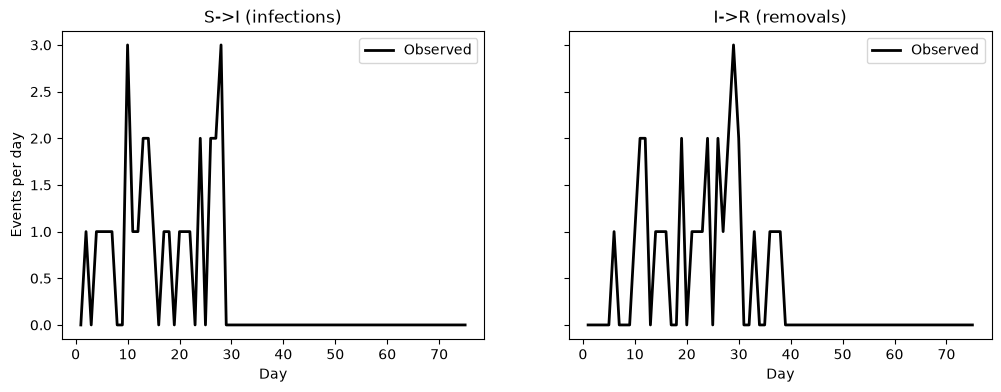

In [5]:
pop_size = 50

small_initial_state = np.zeros((pop_size, 3))
small_initial_state[:, 0] = 1.0                # everyone susceptible...
small_initial_state[0] = [0.0, 1.0, 0.0]       # ...except individual 0, who is infectious


def homogeneous_si_rate(t, state):
    num_infectious = state[:, 1].sum()
    return 0.3 * num_infectious / pop_size     # beta = 0.3


def homogeneous_ir_rate(t, state):
    return 0.14                                # gamma = 0.14


@tfd.JointDistributionCoroutineAutoBatched
def small_model():
    yield gld.DiscreteTimeStateTransitionModel(
        transition_rate_fn=[homogeneous_si_rate, homogeneous_ir_rate],
        incidence_matrix=sir_incidence_matrix,
        initial_state=small_initial_state,
        num_steps=75,
        name="sir",
    )


true_epidemic = small_model.sample(seed=jax.random.key(2))
true_events = np.asarray(true_epidemic.sir)
true_infection_day = infection_days(true_events)
infected = np.where(true_events[:, :, 0].sum(axis=0) > 0)[0]   # who was infected
print(f"{len(infected)} of {pop_size} individuals were infected")

plot_incidence(true_events)

### The move events sampler in `gemlib`

`gemlib` provides the move events algorithm as `mcmc.discrete_time_state_transition_model.move_events`.  Its settings are:

- `transition_index=0`: move S→I events (column 0 of the incidence matrix), leaving the observed I→R events alone;
- `delta_max`: the largest move, in days ($\delta_{max}$ above);
- `num_units`: how many units' (here, individuals') infections to move together in one proposal;
- `count_max=1`: the most events to move from a single unit; each unit here is one person, with one infection.

Each proposal moves only one person's infection, so to give everyone a chance to move we repeat the step several times in each iteration: `5 * move_kernel` means "do `move_kernel` five times".

As in the previous workshop, `mcmc.MwgStep` says which variable the sampler updates (`target_names="sir"`).  The move sampler also needs the initial conditions, which `kernel_kwargs_fn` supplies.

The function below builds the sampler with the settings we give it, runs it for 2000 iterations starting from the true epidemic (in a real analysis we'd start from a plausible guess), and prints the acceptance rate.  Because the parameters are fixed, the target is just `small_model.log_prob`.  Each run takes about 20 seconds.

In [6]:
def run_move_sampler(delta_max, num_units=1, num_moves=5, seed=0):
    move_kernel = mcmc.MwgStep(
        mcmc.discrete_time_state_transition_model.move_events(
            incidence_matrix=sir_incidence_matrix,
            transition_index=0,
            num_units=num_units,
            delta_max=delta_max,
            count_max=1,
        ),
        target_names="sir",
        kernel_kwargs_fn=lambda position: {"initial_conditions": small_initial_state},
    )
    samples, info = jax.jit(
        lambda seed: mcmc.mcmc(
            num_samples=2000,
            sampling_algorithm=num_moves * move_kernel,
            target_log_density_fn=small_model.log_prob,
            initial_position=true_epidemic,
            seed=seed,
        )
    )(jax.random.key(seed))
    info = info.last_results   # acceptance information for the last of the repeated moves
    print(f"delta_max = {delta_max}, num_units = {num_units}, num_moves = {num_moves}: "
          f"acceptance rate {np.mean(info.is_accepted):.2f}")
    return samples


small_samples = run_move_sampler(delta_max=5)

delta_max = 5, num_units = 1, num_moves = 5: acceptance rate 0.48


`small_samples.sir` holds 2000 sampled epidemics, all with exactly the observed removal times.  The helper function `infection_days` finds each individual's infection day in every sample.  Here are the trace plots and posterior distributions of the infection day for four individuals, with the true day marked in red.  We discard the first 500 iterations as burn-in.

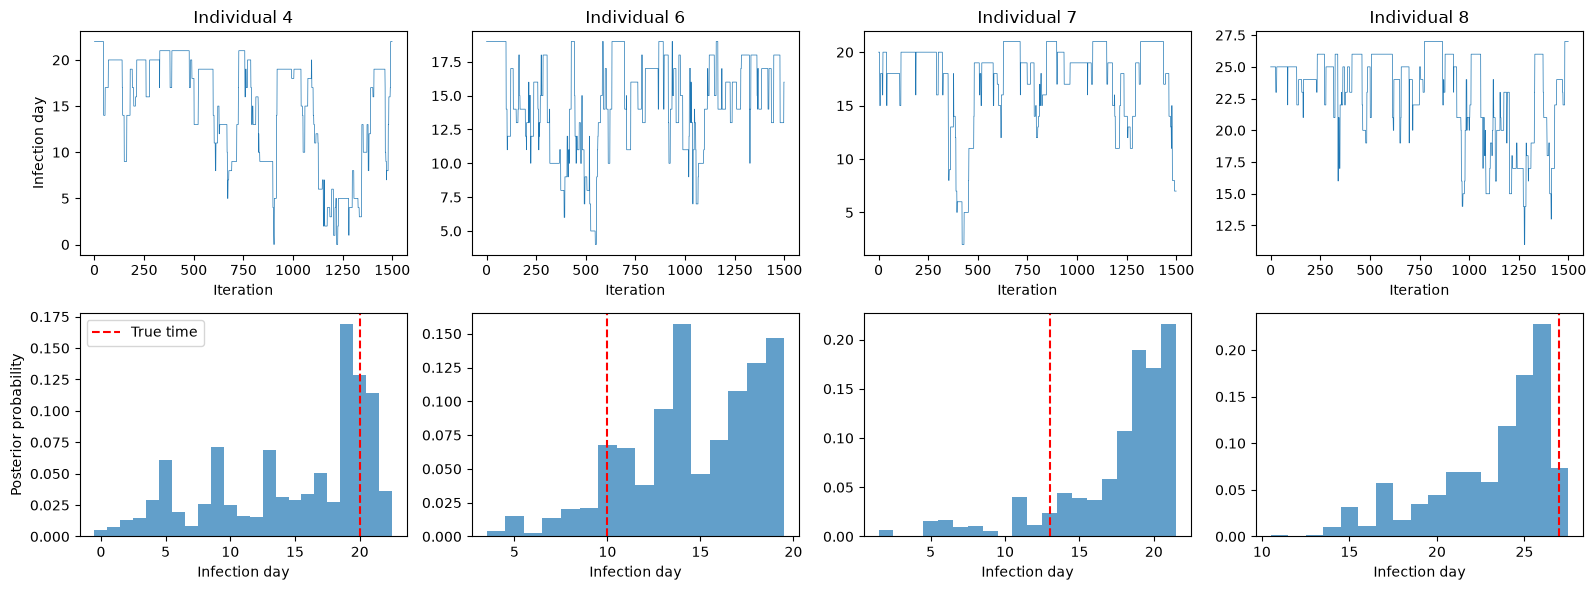

In [7]:
plot_infection_time_posteriors(infection_days(small_samples.sir)[500:], true_infection_day, people=infected[1:5])

Each individual's infection day now has a posterior distribution spread over several days: given only the removal times (and the parameters), that's how much we can say about when they were infected.  The true day sits within it, but not necessarily at its peak.

Some of these distributions are very wide.  In a homogeneously mixing model, anyone could have infected anyone, so the only things that pin down an individual's infection time are their own removal time and the overall shape of the epidemic.  In a network model like the Hagelloch one, who is connected to whom adds a lot more information.

Putting everyone together gives the posterior distribution of the infection curve (blue), alongside the true one (black):

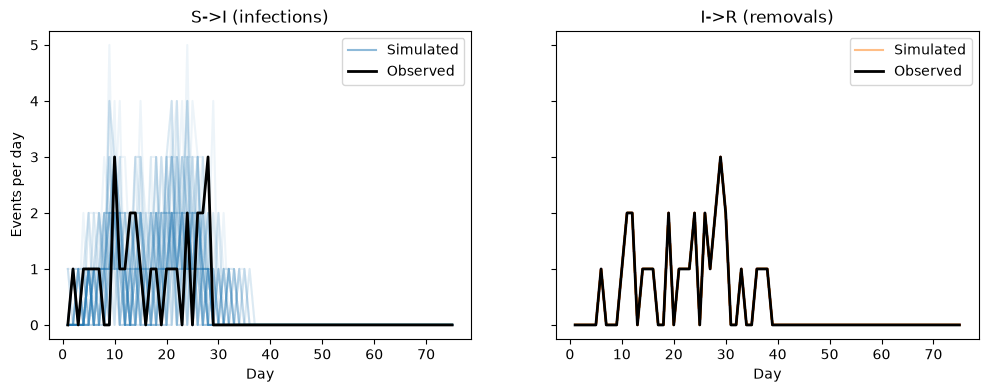

In [8]:
plot_incidence(true_events, small_samples.sir[500::30])

````{exercise-start}
:label: da-ex1
````

`delta_max` is the "step size" of the move sampler.

1. Run the sampler with `delta_max=1` and `delta_max=20`, e.g. `samples_1 = run_move_sampler(delta_max=1)`, and plot the results with `plot_infection_time_posteriors` as above.
2. How do the acceptance rates and the trace plots compare with `delta_max=5`?  Which would you choose, and why?

In [9]:
# your code here

````{exercise-end}
````

````{solution-start} da-ex1
:class: dropdown
````

delta_max = 1, num_units = 1, num_moves = 5: acceptance rate 0.82


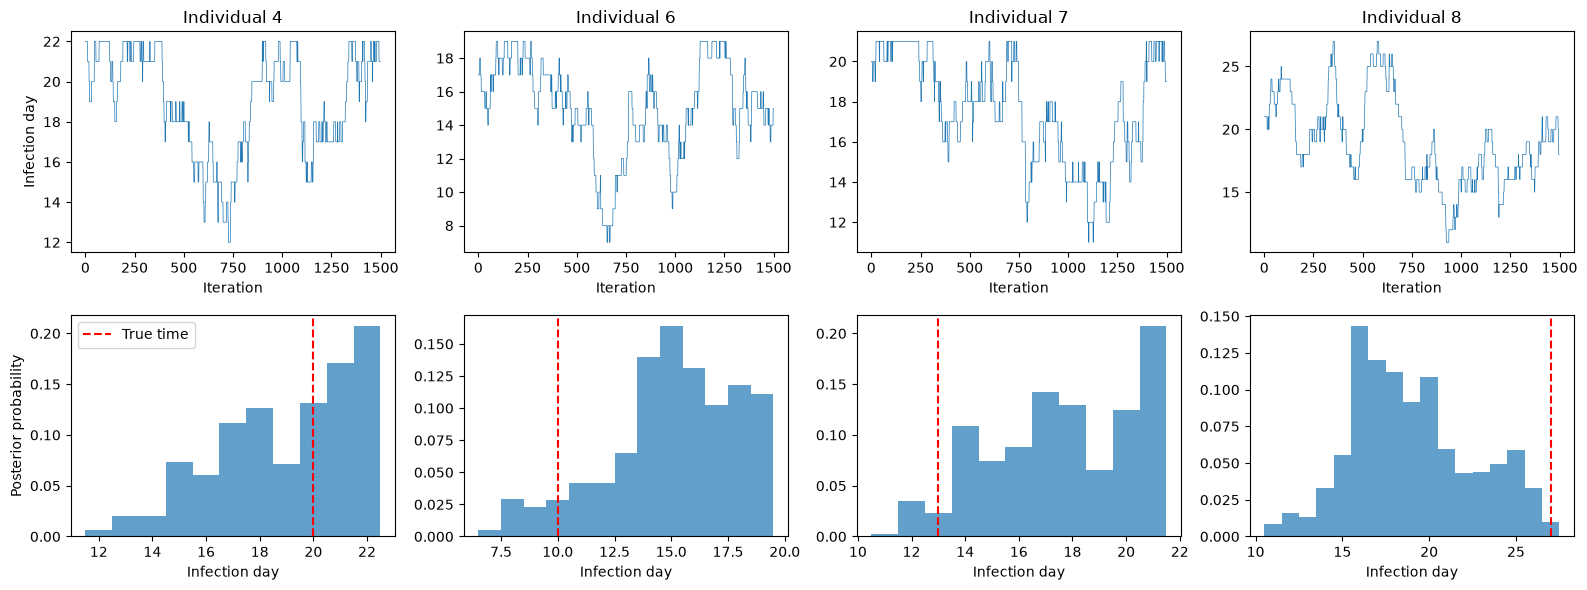

delta_max = 20, num_units = 1, num_moves = 5: acceptance rate 0.03


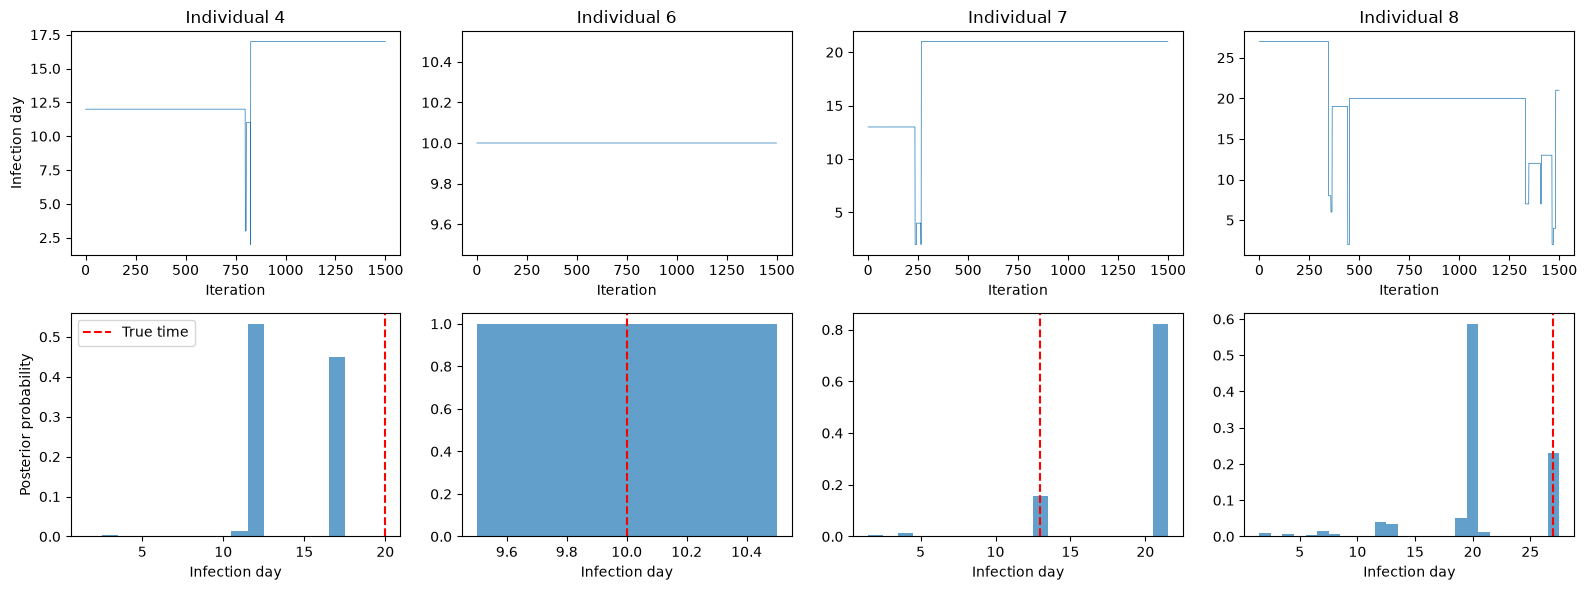

In [10]:
for delta_max in [1, 20]:
    samples_d = run_move_sampler(delta_max=delta_max)
    plot_infection_time_posteriors(infection_days(samples_d.sir)[500:], true_infection_day, people=infected[1:5])

This is the same trade-off as for the proposal scale of the random walk sampler in the Bayes and MCMC workshop.  With `delta_max=1`, most moves are accepted, but each one is tiny, so infection times wander slowly.  With `delta_max=20`, most moves land somewhere implausible (after the individual's removal, say) and are rejected, so the traces stick at the same value for long stretches.  A moderate value, like 5, explores best.

````{solution-end}
````

````{exercise-start}
:label: da-ex2
````

So far each iteration has made five separate proposals, each moving one person's infection (`num_moves=5`, `num_units=1`).  Another way to move five infections per iteration is a single proposal that moves five people's infections together: `run_move_sampler(delta_max=5, num_units=5, num_moves=1)`.

1. Try it.  What happens to the acceptance rate and the trace plots?  Why?
2. Which approach would you use for Hagelloch?

In [11]:
# your code here

````{exercise-end}
````

````{solution-start} da-ex2
:class: dropdown
````

delta_max = 5, num_units = 5, num_moves = 1: acceptance rate 0.05


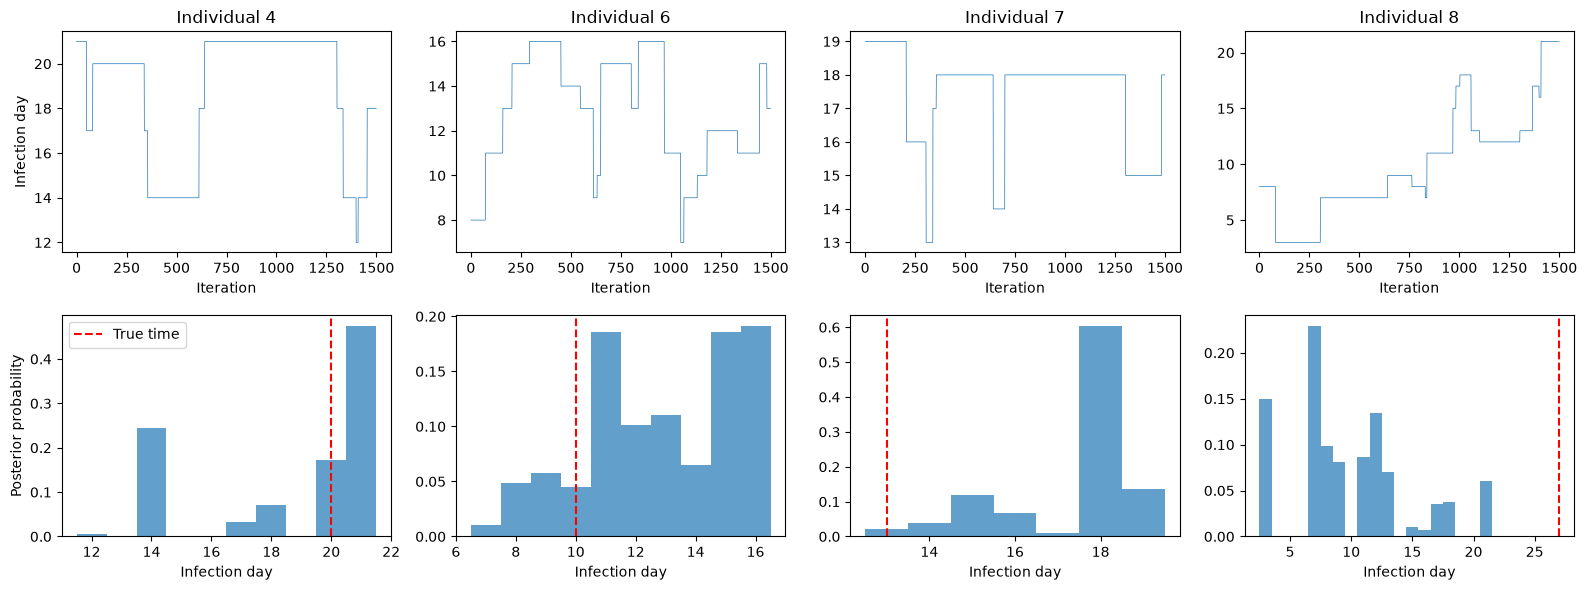

In [12]:
samples_u = run_move_sampler(delta_max=5, num_units=5, num_moves=1)
plot_infection_time_posteriors(infection_days(samples_u.sir)[500:], true_infection_day, people=infected[1:5])

The acceptance rate collapses, and the traces stick for long stretches.  A proposal that moves several infections is accepted or rejected as a whole, so if any one of the moves is implausible, the whole proposal is likely to be rejected, taking the good moves with it.  Five separate single-infection proposals attempt the same number of moves, but each is accepted or rejected on its own merits.  That's why, in Part 4, we repeat a single-child move five times in each iteration.

````{solution-end}
````

### Beyond moving events

Moving infections around within the observation window isn't always enough.  Depending on what was observed, a sampler may also need to:

- **change the initial conditions** (_left censoring_): who was already infectious when observation started, and when were they infected?

![Left censored add event](https://gem-epidemics.gitlab.io/practical-epidemics/_static/images/iddinf/lh_add_event.png "Left censored add event")

- **add or delete infections at the end of the window** (_right censoring_): if the epidemic is still going when observation stops, some individuals may have been infected but not yet removed;

![Right censored add event](https://gem-epidemics.gitlab.io/practical-epidemics/_static/images/iddinf/rh_add_event.png "Right censored add event")

![Right censored delete event](https://gem-epidemics.gitlab.io/practical-epidemics/_static/images/iddinf/rh_del_event.png "Right censored delete event")

- **add or delete infections that were never observed at all** (_occult_ infections), for example mild cases that were never reported.

![Add event](https://gem-epidemics.gitlab.io/practical-epidemics/_static/images/iddinf/add_event.png "Add event")

Coding all of these efficiently and correctly is a substantial piece of work, so `gemlib` provides samplers for each of them in `gemlib.mcmc.discrete_time_state_transition_model`: `move_events`, `left_censored_events_mh` and `right_censored_events_mh`.

````{exercise-start}
:label: da-ex3
````

Which of these situations apply to the Hagelloch data?  Think about: did everyone get infected, did the epidemic finish within the data, and do we know when the first child was infected?

````{exercise-end}
````

````{solution-start} da-ex3
:class: dropdown
````

Every child in the dataset was eventually infected and removed, so there are no unobserved infections to add, and since the epidemic was over by the end of the data, there is no right censoring.  But we don't really know who was infected first, or when: the index case's infection time is as uncertain as everyone else's.  So for Hagelloch we need to **move** infection times and to handle **left censoring** (the initial conditions).

````{solution-end}
````


----

## Part 4: Data augmentation for Hagelloch in `gemlib`

We now build a data augmentation sampler for the Hagelloch model, following the Metropolis-within-Gibbs recipe from Part 2.  Each iteration does the following:

1. Update the six parameters, one at a time, with `param_kernel` (exactly as in the previous workshop).
2. Five times over:
    1. move one child's infection time (`move_events`);
    2. update the initial conditions and early infection times (`left_censored_events_mh`).

### The samplers

`move_events` is the sampler from Part 3, with the same settings: move S→I events (`transition_index=0`), one child at a time (`num_units=1`, `count_max=1`), by up to 5 days (`delta_max=5`).

`left_censored_events_mh` proposes to swap an infection near the start of the epidemic (within the first `max_timepoint=10` days) with an "already infectious" entry in the initial conditions, and vice versa.  This lets the sampler explore who the index case was, and when they were infected.

As before, `mcmc.MwgStep` tells each sampler which variables of the model it updates.  The move sampler also needs to know the initial conditions, which `kernel_kwargs_fn` supplies.  See the [`gemlib` documentation](https://gem-epidemics.gitlab.io/gemlib/gemlib.mcmc.html#discrete-time-state-transition-model-kernels) for the details.

In [13]:
move_kernel = mcmc.MwgStep(
    mcmc.discrete_time_state_transition_model.move_events(
        incidence_matrix=sir_incidence_matrix,
        transition_index=0,
        num_units=1,
        delta_max=5,
        count_max=1,
    ),
    target_names="sir",
    kernel_kwargs_fn=lambda position: {"initial_conditions": position.initial_conditions},
)

left_censored_kernel = mcmc.MwgStep(
    mcmc.discrete_time_state_transition_model.left_censored_events_mh(
        incidence_matrix=sir_incidence_matrix,
        transition_index=0,
        max_timepoint=10,
        max_events=1,
        events_varname="sir",
        initial_conditions_varname="initial_conditions",
    ),
    target_names=["initial_conditions", "sir"],
)

da_kernel = param_kernel >> 20 * (move_kernel >> left_censored_kernel)

Notice how we reused `param_kernel` unchanged and just chained the new samplers on to it.  `5 * (...)` repeats a step five times within each iteration.

Since the sampler now updates **every** variable in the model, including `sir` and `initial_conditions`, nothing is pinned: the target is the log density of the full `joint_model`.  We start from sensible parameter values and the recorded infection times.

In [14]:
da_initial_position = joint_model.sample(
    household=0.01, class1=0.04, class2=0.01, distance=0.001, spatial_decay=0.01, removal_rate=0.14,
    sir=events, initial_conditions=initial_conditions,
    seed=jax.random.key(45),
)
print("Log joint density at the starting point:", joint_model.log_prob(da_initial_position))

Log joint density at the starting point: -1195.7068956068315


### Running the samplers

To see what difference data augmentation makes, we'll run two samplers:

- the sampler from the previous workshop, which treats the recorded infection times as known (about 1–2 minutes);
- the data augmentation sampler (about 8–10 minutes: be prepared to get a coffee!).

Every sample of the data augmentation sampler includes a complete epidemic, an array of 54 × 187 × 2 numbers, so storing all 5000 of them would need about 800 MB of memory.  To keep things manageable, we run the sampler in 10 blocks of 500 iterations, each block carrying on from where the last one finished.  The helper function `run_in_blocks` does this, keeping every sample of the parameters but only every 50th sample of the epidemic and the initial conditions.

In [15]:
conditioned_model = joint_model.experimental_pin(sir=events, initial_conditions=initial_conditions)
known_initial_position = conditioned_model.sample_unpinned(seed=jax.random.key(0))._replace(
    household=0.01, class1=0.04, class2=0.01, distance=0.001, spatial_decay=0.01, removal_rate=0.14
)


@jax.jit
def run_known_times_sampler(seed):
    return mcmc.mcmc(
        num_samples=1500,
        sampling_algorithm=param_kernel,
        target_log_density_fn=conditioned_model.log_prob,
        initial_position=known_initial_position,
        seed=seed,
    )


known_samples, known_info = run_known_times_sampler(jax.random.key(42))

In [16]:
@jax.jit
def run_da_mcmc(position, seed):
    return mcmc.mcmc(
        num_samples=1500,
        sampling_algorithm=da_kernel,
        target_log_density_fn=joint_model.log_prob,
        initial_position=position,
        seed=seed,
    )

da_samples, da_info = run_da_mcmc(da_initial_position, seed=jax.random.key(45))

```{warning}
To keep the workshop to time, we've run far fewer iterations than this sampler really needs.  [Experience suggests](https://projecteuclid.org/journals/bayesian-analysis/volume-4/issue-3/Bayesian-analysis-for-emerging-infectious-diseases/10.1214/09-BA417.full) that updating around 10% of the infection times per iteration works well (here, about 20 repetitions of the move and left-censoring steps), and that many more than 1500 iterations are needed for reliable inference.
```

### Checking the run

The `da_info` data structure contains a `RwmhInfo` object for each parameter sampler, and a `MultiScanKernelInfo` object for the compound `(move_kernel >> left_censored_kernel` multiscan kernel.  Let's dig out the acceptance rates:

In [17]:
for name, info in zip(PARAM_NAMES, da_info):
    print(f"Acceptance {name}: {np.mean(info.is_accepted):.2f}")

da_kernel_info = da_info[-1].last_results
print(f"Acceptance move: {np.mean(da_kernel_info[0].is_accepted):.2f}")
print(f"Acceptance move: {np.mean(da_kernel_info[1].is_accepted):.2f}")

Acceptance household: 0.42
Acceptance class1: 0.42
Acceptance class2: 0.57
Acceptance distance: 0.37
Acceptance spatial_decay: 0.57
Acceptance removal_rate: 0.34
Acceptance move: 0.33
Acceptance move: 0.99


````{exercise-start}
:label: da-ex4
````

1. Draw trace plots with `trace_plots(da_samples, burn_in=1000)` and print a summary with `summarise(da_samples, burn_in=1000)`.  How does the mixing compare with the known-times sampler (`trace_plots(known_samples, burn_in=1000)`)?
2. Compare the two posteriors with `compare_posteriors(known_samples, da_samples, ["Known infection times", "Data augmentation"])`.  Which parameters change most?  Why might that be?

In [18]:
# your code here

````{exercise-end}
````

````{solution-start} da-ex4
:class: dropdown
````

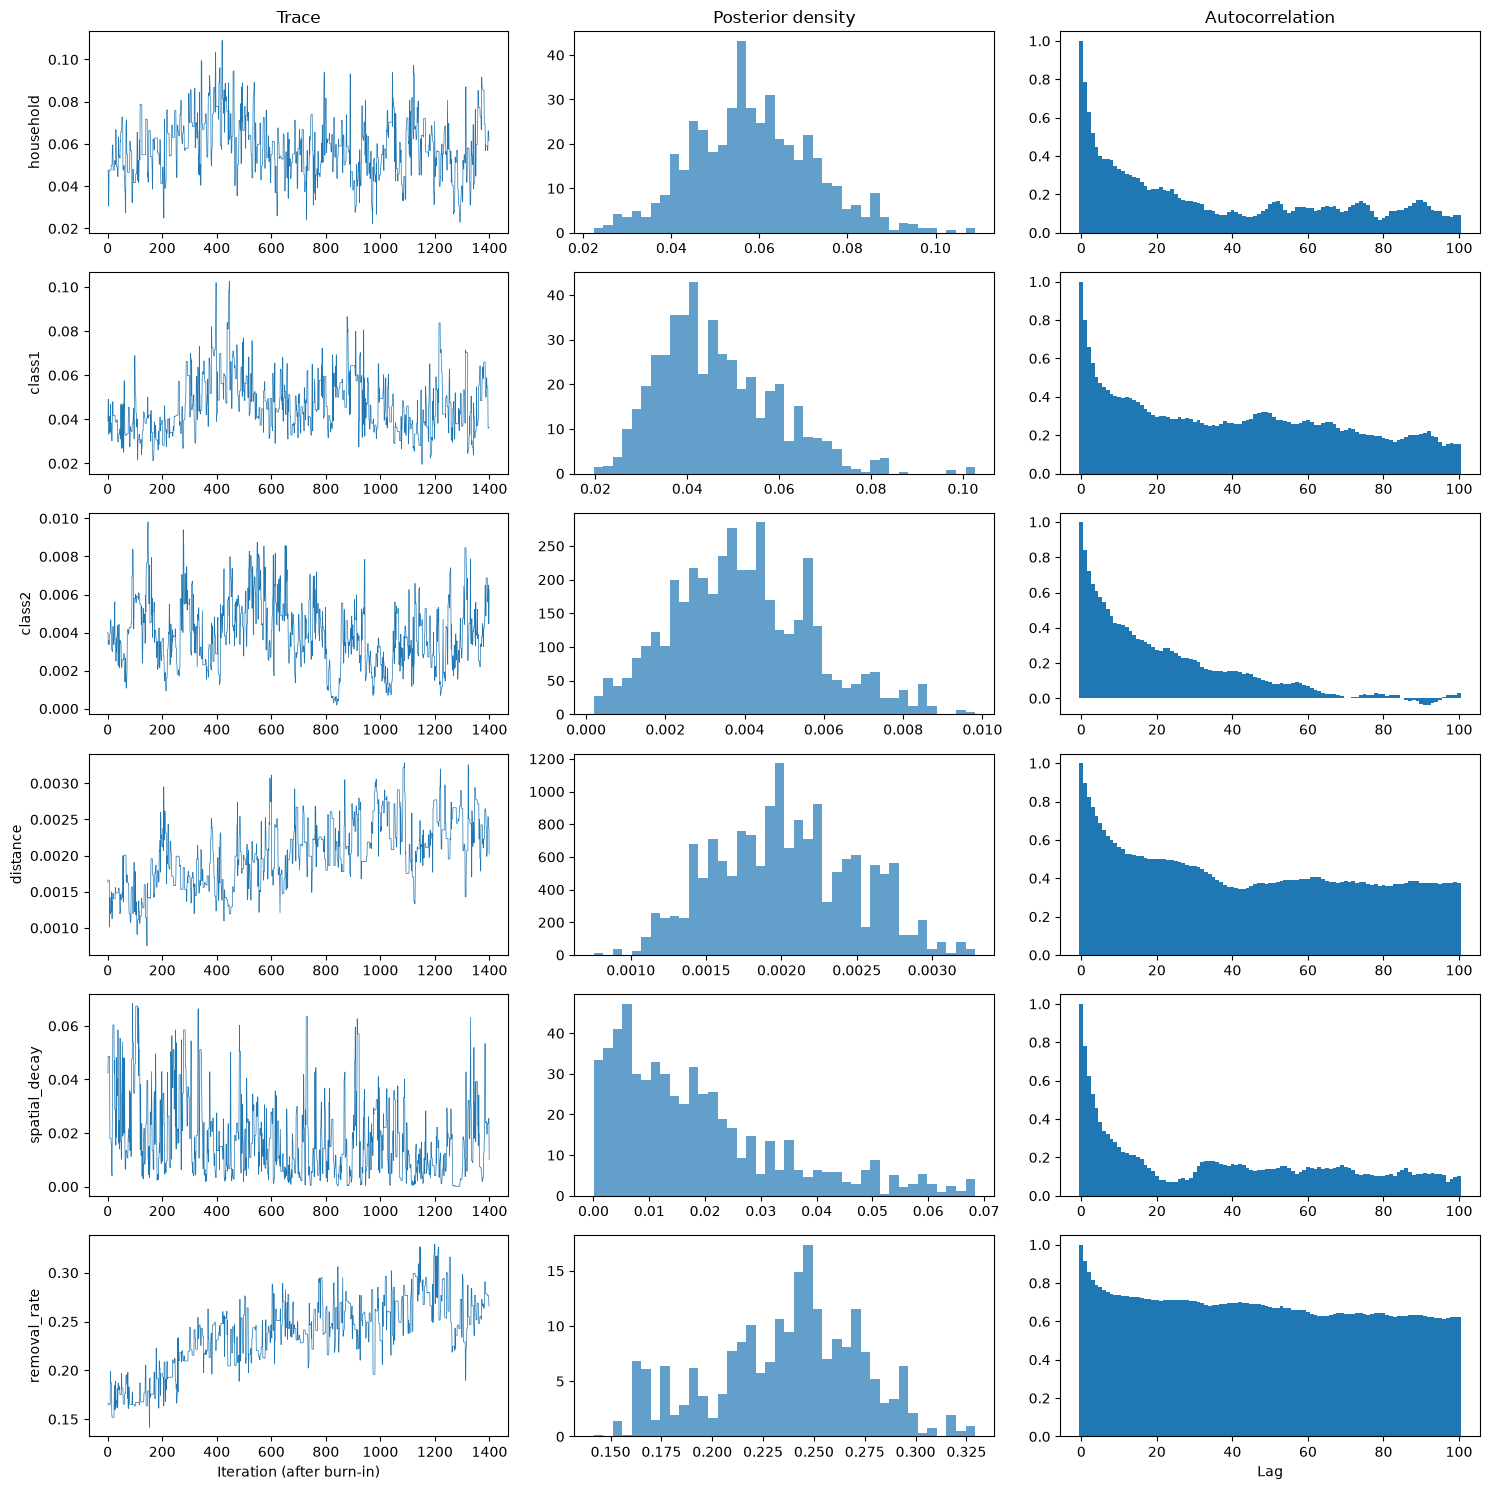

parameter            mean      2.5%     97.5%     ESS
household          0.0586    0.0312    0.0882      35
class1             0.0465    0.0274    0.0732      22
class2             0.0040    0.0008    0.0079      44
distance           0.0020    0.0012    0.0029       6
spatial_decay      0.0185    0.0004    0.0585      41
removal_rate       0.2366    0.1648    0.2995       5


In [19]:
trace_plots(da_samples, burn_in=100)
summarise(da_samples, burn_in=100)

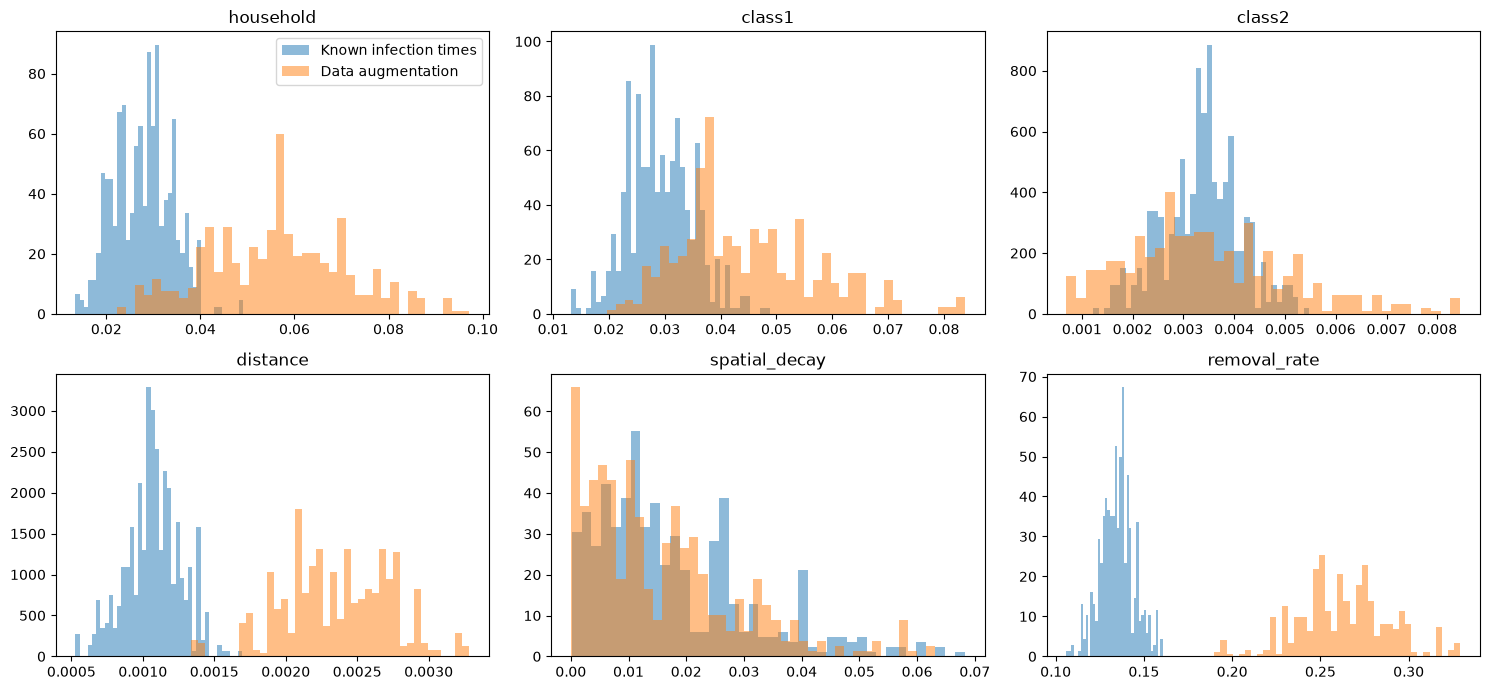

In [20]:
compare_posteriors(known_samples, da_samples, ["Known infection times", "Data augmentation"])

The data augmentation sampler mixes **much** worse.  The trace plots wander slowly, the autocorrelations take hundreds of iterations to die away, and the effective sample sizes have collapsed from several hundred to a few tens or fewer.  This is the price of exploring the infection times as well as the parameters, and it's why the warning above says that 1500 iterations is far too few: treat these results as illustrative, not final.

Even so, the posteriors move a long way:

- the **removal rate** $\gamma$ rises from about 0.135 to about 0.19, i.e. the mean infectious period falls from about 7.4 to about 5 days.  Each child's infectious period is the gap between their infection and removal, so once the infection times are free to move, $\gamma$ is no longer pinned down by the recorded ones.  The strong dependence between $\gamma$ and the infection times is also the main reason for the poor mixing: neither can change much without the other;
- the **household** rate roughly triples, from about 0.03 to about 0.10.  One explanation is that, given freedom to move, the sampler places the infections of children in the same household closer together in time, which household transmission explains well;
- the other parameters change less, but their posteriors are generally wider, as we'd expect now that we're admitting we don't know the infection times.

````{solution-end}
````

### What happened to the infection times?

Dropping the first 100 iterations as burn-in and plotting the rest shows the posterior distribution of the infection curve, alongside the recorded infection times.  The removals don't change, because they were observed.

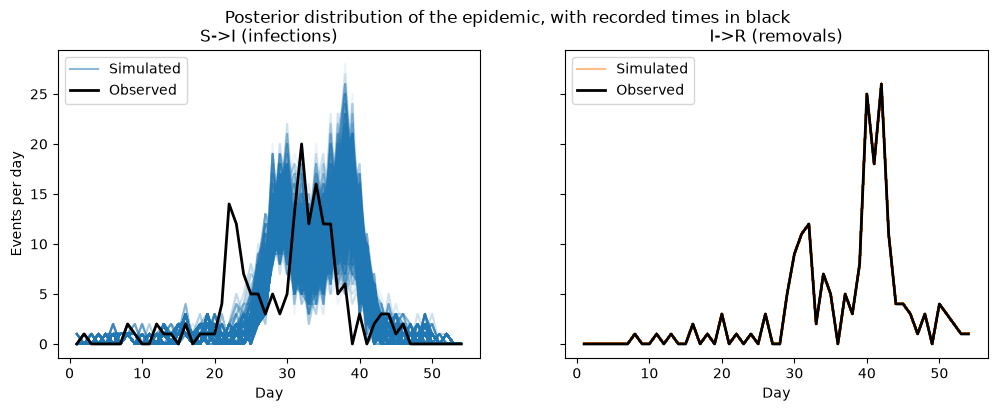

In [21]:
plot_incidence(events, da_samples.sir[100:], title="Posterior distribution of the epidemic, with recorded times in black")

### Checking the fit again

Finally, the posterior predictive check from the previous workshop.  For each posterior sample, we simulate a completely new epidemic from day 0.  For the data augmentation posterior, each sample also includes its own initial conditions, so we use those too.

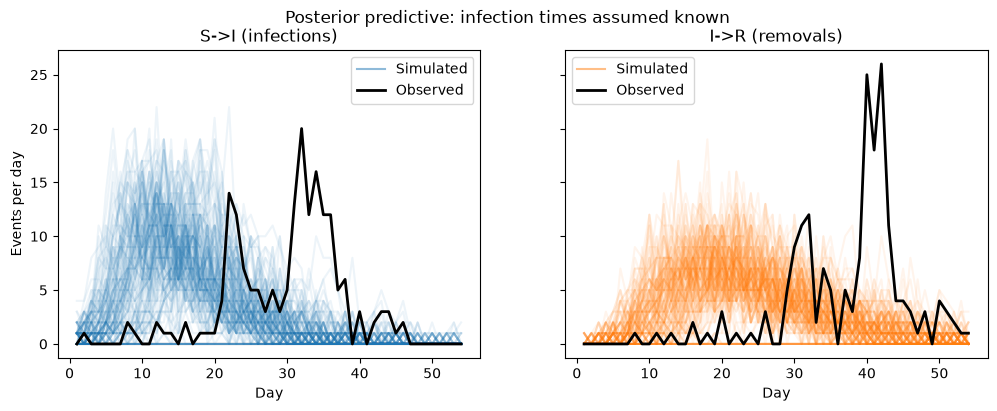

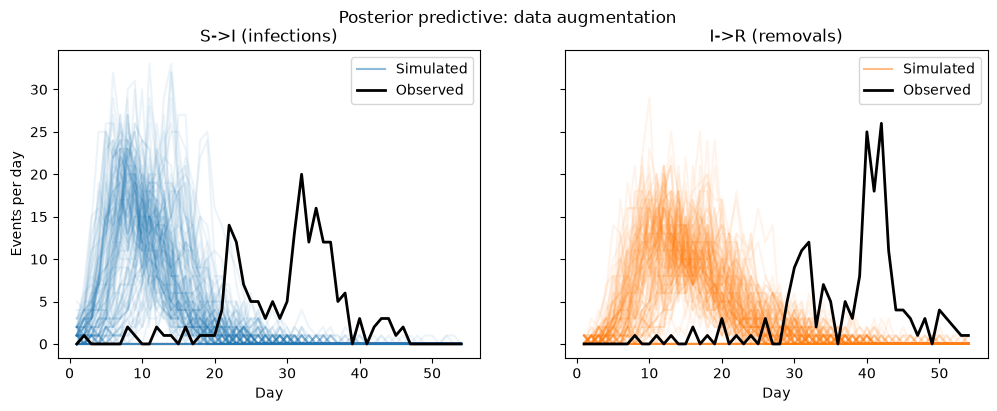

In [22]:
def simulate_one(household, class1, class2, distance, spatial_decay, removal_rate, initial_conditions, seed):
    model = hagelloch_sir(household, class1, class2, distance, spatial_decay, removal_rate,
                          initial_conditions)
    return model.sample(seed=seed)


def posterior_predictive(samples, initial_conditions_draws, seed):
    # every 10th sample after 100 iterations burn-in
    thinned = [np.asarray(getattr(samples, name))[100::10] for name in PARAM_NAMES]
    num_draws = len(thinned[0])
    return jax.vmap(simulate_one)(
        *thinned,
        initial_conditions=initial_conditions_draws[:num_draws],
        seed=jax.random.split(seed, num_draws),
    )


# Known times: everyone starts from the recorded initial conditions
known_ic = np.repeat(initial_conditions[np.newaxis], 140, axis=0)
known_predictive = posterior_predictive(known_samples, known_ic, jax.random.key(44))

# Data augmentation: each sample has its own initial conditions
da_ic = da_samples.initial_conditions
da_predictive = posterior_predictive(da_samples, da_ic, jax.random.key(44))

plot_incidence(events, known_predictive, title="Posterior predictive: infection times assumed known")
plot_incidence(events, da_predictive, title="Posterior predictive: data augmentation")

````{exercise-start}
:label: da-ex5
````

We now have two quite different pictures of the epidemic from the data augmentation run: the **posterior distribution of the epidemic** (the plot of `da_samples.sir`), and the **posterior predictive distribution** (the last plot).

1. How well does each of them match the observed data?  How does the data augmentation posterior predictive compare with the one that assumes the infection times are known?
2. Why do the two pictures look so different?  Think about what each one is conditioned on.
3. What do the results suggest about the recorded infection times, and about the model itself?

````{exercise-end}
````

````{solution-start} da-ex5
:class: dropdown
````

**1.** The posterior distribution of the epidemic matches the data closely.  The sampled infection curves follow the recorded ones, except that the first wave, around day 22, has been moved later and merged into the main wave around days 28 to 40.  The posterior predictive distribution, on the other hand, fits no better than before, and arguably worse: the simulated epidemics take off immediately and peak around days 10 to 15, well before the real outbreak got going.

**2.** The posterior distribution of the epidemic is conditioned on the data: every sampled history has exactly the observed removal times, so the infections can only sit a few days before them.  The posterior predictive simulations are conditioned only on the parameters (and the initial conditions): each one runs the model forward freely from day 0.  So the posterior of the epidemic tells us what probably happened, given everything we observed, while the posterior predictive tells us whether the model, with the fitted parameters, can _generate_ epidemics like the one we saw.

**3.** The posterior of the epidemic suggests that the recorded infection times are not entirely consistent with the model: given the removal times, the model prefers to place the first-wave infections several days later than recorded.  It's hard to know in 2026 how accurate the 1861 records, or the way the infection times were worked back from symptoms, really are.

The posterior predictive check tells us something different: the model itself is missing something.  Whatever the infection times, a model with constant transmission rates can't reproduce the real outbreak's quiet first three weeks followed by rapid spread.  Possible culprits include changes over time (for example, in school attendance), or features of the index case and early transmission that the model doesn't capture.  Data augmentation deals with _missing data_; it can't fix a _misspecified model_.  (And with effective sample sizes this small, a much longer run would be needed before trusting the details.)  Checking the fit in both ways, and asking why they disagree, is how we'd go about improving the model.

````{solution-end}
````


----

## Wrap-up

Today we have:

- seen why missing infection times make the likelihood of an epidemic model impossible to compute directly;
- met data augmentation: treating the missing times as unknowns, and sampling them with the parameters in a Metropolis-within-Gibbs sampler;
- used `gemlib`'s move events sampler on a small example, and seen how its settings affect the acceptance rate and mixing;
- met the boundary cases (left and right censoring, occult infections) that further samplers handle;
- built a data augmentation sampler for the Hagelloch epidemic in `gemlib`, compared it with one that assumes the infection times are known, and seen how a posterior predictive check can reveal what a model is missing.

### Where next?

- Data augmentation samplers mix slowly, because parameters and event times are strongly correlated.  More recent algorithms, such as individual-level forward-filtering backward-sampling, update a whole individual's history at once and show a lot of promise.
- `gemlib`'s `right_censored_events_mh` handles epidemics that are still going when the data end, which is the usual situation in real time during an outbreak.
- The [`gemlib` documentation](https://gem-epidemics.gitlab.io/gemlib) describes these samplers and others, including gradient-based samplers for the parameters.